In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd
df=pd.read_csv("StudentsPerformance.csv")
print("Data loaded Successfully")

Data loaded Successfully


In [4]:
df.head()
df.head(10)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
5,female,group B,associate's degree,standard,none,71,83,78
6,female,group B,some college,standard,completed,88,95,92
7,male,group B,some college,free/reduced,none,40,43,39
8,male,group D,high school,free/reduced,completed,64,64,67
9,female,group B,high school,free/reduced,none,38,60,50


In [5]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [6]:
df.sample(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
560,female,group D,some college,standard,completed,74,75,79
820,female,group A,some high school,standard,completed,85,90,92
323,female,group C,some high school,free/reduced,none,43,53,53
927,female,group D,high school,free/reduced,completed,65,61,71
982,male,group B,some high school,standard,completed,79,85,86


In [7]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\n--- Data Types & Info ---")
print(df.info())

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Duplicates Check ---")
print(f"Duplicate rows: {df.duplicated().sum()}")

print("\n--- Descriptive Statistics ---")
df.describe()

Shape: (1000, 8)

Columns: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

--- Data Types & Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
None

--- Missing Values Check ---
gender                         0
race/eth

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [8]:
# 1. Missing values - if any, fill with mode for categorical, median for numerical
 #df['parental level of education'].fillna(df['parental level of education'].mode()[0], inplace=True)

# 2. Duplicates - remove if found
if df.duplicated().sum() > 0:
    df = df.drop_duplicates()
    print("Duplicates removed")
else:
    print("No missing values and no duplicates found - Data is clean")

# Check again
df.isnull().sum()

No missing values and no duplicates found - Data is clean


gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [9]:
# Check unique values and clean spaces / lower case issues
cat_cols = ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

for col in cat_cols:
    print(f"{col}: {df[col].unique()}")

# Standardize text: strip spaces, lower case then title case for consistency
for col in cat_cols:
    df[col] = df[col].str.strip().str.lower()

# Optional: Convert back to proper format for report
df['gender'] = df['gender'].str.title()
df['lunch'] = df['lunch'].str.title()

df.head()

gender: ['female' 'male']
race/ethnicity: ['group B' 'group C' 'group A' 'group D' 'group E']
parental level of education: ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
lunch: ['standard' 'free/reduced']
test preparation course: ['none' 'completed']


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,Female,group b,bachelor's degree,Standard,none,72,72,74
1,Female,group c,some college,Standard,completed,69,90,88
2,Female,group b,master's degree,Standard,none,90,95,93
3,Male,group a,associate's degree,Free/Reduced,none,47,57,44
4,Male,group c,some college,Standard,none,76,78,75


In [10]:
# 1. Total Score
df['total_score'] = df['math score'] + df['reading score'] + df['writing score']

# 2. Average Score
df['average_score'] = df['total_score'] / 3

# 3. Percentage Performance (out of 300)
df['percentage'] = (df['total_score'] / 300) * 100

# 4. Pass/Fail Status - let's define Pass if average >= 40 (you can change to 50)
# And overall pass if all subjects >= 40
pass_mark = 40
df['pass_status'] = np.where(df['average_score'] >= pass_mark, 'Pass', 'Fail')

# More detailed status: Pass only if all 3 subjectsd >= 40
df['overall_pass'] = np.where(
    (df['math score'] >= pass_mark) & (df['reading score'] >= pass_mark) & (df['writing score'] >= pass_mark),
    'Pass', 'Fail'
)

df[['math score','reading score','writing score','total_score','average_score','percentage','pass_status']].head(10)

,math score,reading score,writing score,total_score,average_score,percentage,pass_status
0,72,72,74,218,72.666667,72.666667,Pass
1,69,90,88,247,82.333333,82.333333,Pass
2,90,95,93,278,92.666667,92.666667,Pass
3,47,57,44,148,49.333333,49.333333,Pass
4,76,78,75,229,76.333333,76.333333,Pass
5,71,83,78,232,77.333333,77.333333,Pass
6,88,95,92,275,91.666667,91.666667,Pass
7,40,43,39,122,40.666667,40.666667,Pass
8,64,64,67,195,65.000000,65.000000,Pass
9,38,60,50,148,49.333333,49.333333,Pass


In [11]:
print(df.columns)

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score', 'total_score', 'average_score', 'percentage',
       'pass_status', 'overall_pass'],
      dtype='object')


In [14]:
num_cols = ['math score', 'reading score', 'writing score']

for col in num_cols:
    print(col)
    print(df[col].describe())

math score
count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64
reading score
count    1000.000000
mean       69.169000
std        14.600192
min        17.000000
25%        59.000000
50%        70.000000
75%        79.000000
max       100.000000
Name: reading score, dtype: float64
writing score
count    1000.000000
mean       68.054000
std        15.195657
min        10.000000
25%        57.750000
50%        69.000000
75%        79.000000
max       100.000000
Name: writing score, dtype: float64


In [19]:
def detect_outliers(col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    return outliers

In [15]:
for col in num_cols:
    print(col)
    print(df[col].describe())

math score
count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64
reading score
count    1000.000000
mean       69.169000
std        14.600192
min        17.000000
25%        59.000000
50%        70.000000
75%        79.000000
max       100.000000
Name: reading score, dtype: float64
writing score
count    1000.000000
mean       68.054000
std        15.195657
min        10.000000
25%        57.750000
50%        69.000000
75%        79.000000
max       100.000000
Name: writing score, dtype: float64


In [12]:
# Final cleaned and feature engineered dataset
print("Final Shape:", df.shape)
df.head()

# Save for Week 8
df.to_csv('students_performance_cleaned_week7.csv', index=False)

Final Shape: (1000, 13)


In [17]:
# Overall averages
score_cols = ['math score', 'reading score', 'writing score']

print("Overall Mean:")
print(df[score_cols].mean())
print("\nOverall Std:")
print(df[score_cols].std())

# By Gender
print("\n--- By Gender ---")
print(df.groupby('gender')[score_cols + ['average_score']].mean())

# By Race/Ethnicity
print("\n--- By Race/Ethnicity ---")
print(df.groupby('race/ethnicity')[score_cols + ['average_score']].mean().sort_values('average_score', ascending=False))

# By Parental Education
print("\n--- By Parental Education ---")
print(df.groupby('parental level of education')[score_cols + ['average_score']].mean().sort_values('average_score', ascending=False))

# By Lunch
print("\n--- By Lunch Type ---")
print(df.groupby('lunch')[score_cols + ['average_score']].mean())

# By Test Prep
print("\n--- By Test Preparation ---")
print(df.groupby('test preparation course')[score_cols + ['average_score', 'total_score']].mean())

Overall Mean:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

Overall Std:
math score       15.163080
reading score    14.600192
writing score    15.195657
dtype: float64

--- By Gender ---
        math score  reading score  writing score  average_score
gender                                                         
Female   63.633205      72.608108      72.467181      69.569498
Male     68.728216      65.473029      63.311203      65.837483

--- By Race/Ethnicity ---
                math score  reading score  writing score  average_score
race/ethnicity                                                         
group e          73.821429      73.028571      71.407143      72.752381
group d          67.362595      70.030534      70.145038      69.179389
group c          64.463950      69.103448      67.827586      67.131661
group b          63.452632      67.352632      65.600000      65.468421
group a          61.629213      64.674157      62.67415

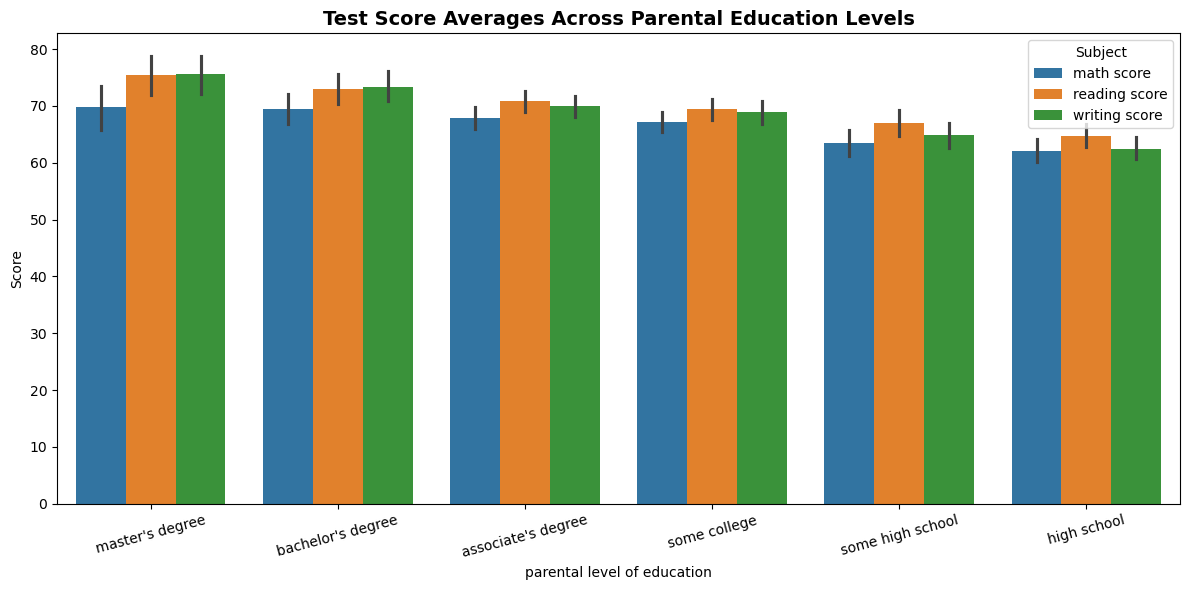

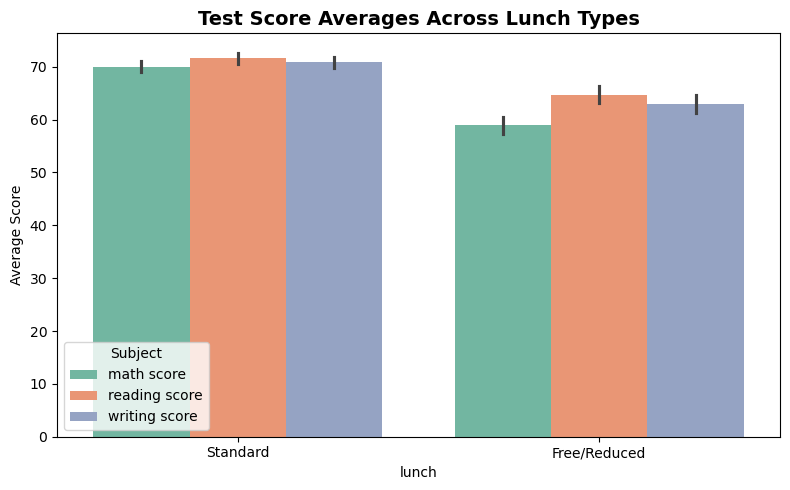

C:\Users\user\AppData\Local\Temp\ipykernel_8724\904467181.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='race/ethnicity', y='average_score', palette='viridis',


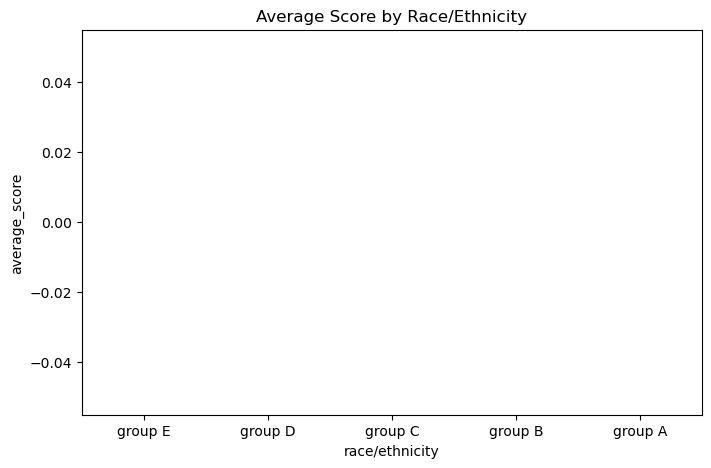

In [20]:
# Melt for seaborn grouped bar chart
df_melt = df.melt(id_vars=['parental level of education'], 
                  value_vars=score_cols, 
                  var_name='Subject', value_name='Score')

# 1. Bar Chart: Parental Level of Education
plt.figure(figsize=(12,6))
sns.barplot(data=df_melt, x='parental level of education', y='Score', hue='Subject', 
            order=["master's degree", "bachelor's degree", "associate's degree", "some college", "some high school", "high school"])
plt.title('Test Score Averages Across Parental Education Levels', fontsize=14, fontweight='bold')
plt.xticks(rotation=15)
plt.legend(title='Subject')
plt.tight_layout()
plt.show()

# 2. Bar Chart: Lunch Type
df_melt_lunch = df.melt(id_vars=['lunch'], value_vars=score_cols, var_name='Subject', value_name='Score')

plt.figure(figsize=(8,5))
sns.barplot(data=df_melt_lunch, x='lunch', y='Score', hue='Subject', palette='Set2')
plt.title('Test Score Averages Across Lunch Types', fontsize=14, fontweight='bold')
plt.ylabel('Average Score')
plt.tight_layout()
plt.show()

# Extra: Gender & Race for equity analysis
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='race/ethnicity', y='average_score', palette='viridis',
            order=['group E','group D','group C','group B','group A'])
plt.title('Average Score by Race/Ethnicity')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_8724\3867953208.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='test preparation course', y='total_score', palette='pastel')
C:\Users\user\AppData\Local\Temp\ipykernel_8724\3867953208.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='test preparation course', y='average_score', palette='pastel')


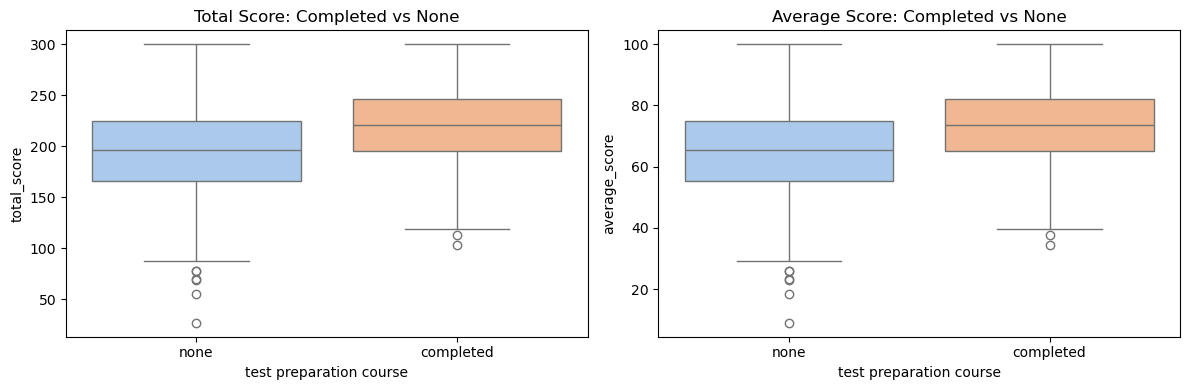

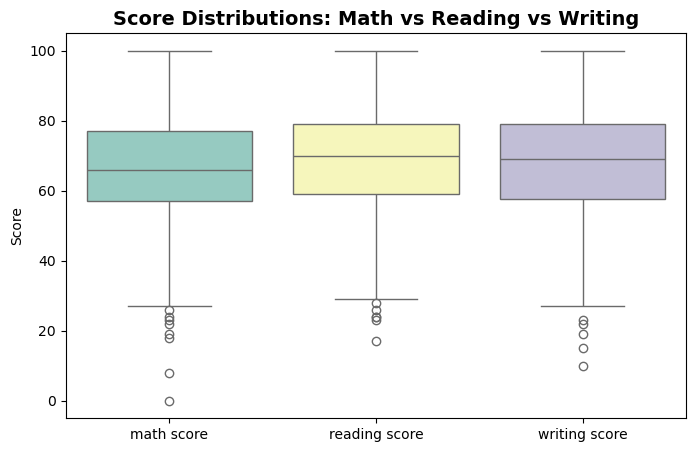

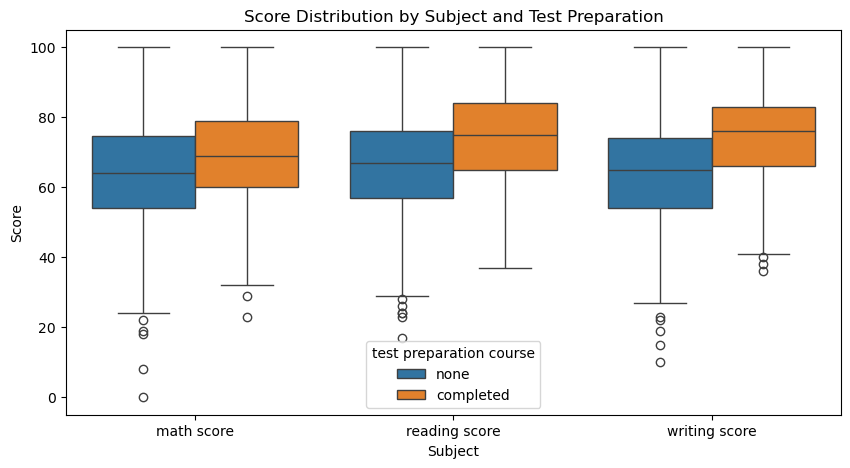

In [21]:
# 1. Box plot: Test Preparation vs Total Score & Average
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
sns.boxplot(data=df, x='test preparation course', y='total_score', palette='pastel')
plt.title('Total Score: Completed vs None')

plt.subplot(1,2,2)
sns.boxplot(data=df, x='test preparation course', y='average_score', palette='pastel')
plt.title('Average Score: Completed vs None')

plt.tight_layout()
plt.show()

# 2. Box plot: Math, Reading, Writing comparison
plt.figure(figsize=(8,5))
sns.boxplot(data=df[score_cols], palette='Set3')
plt.title('Score Distributions: Math vs Reading vs Writing', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.show()

# 3. Box plot: Scores by Test Prep (grouped)
df_melt_prep = df.melt(id_vars=['test preparation course'], value_vars=score_cols, var_name='Subject', value_name='Score')
plt.figure(figsize=(10,5))
sns.boxplot(data=df_melt_prep, x='Subject', y='Score', hue='test preparation course')
plt.title('Score Distribution by Subject and Test Preparation')
plt.show()

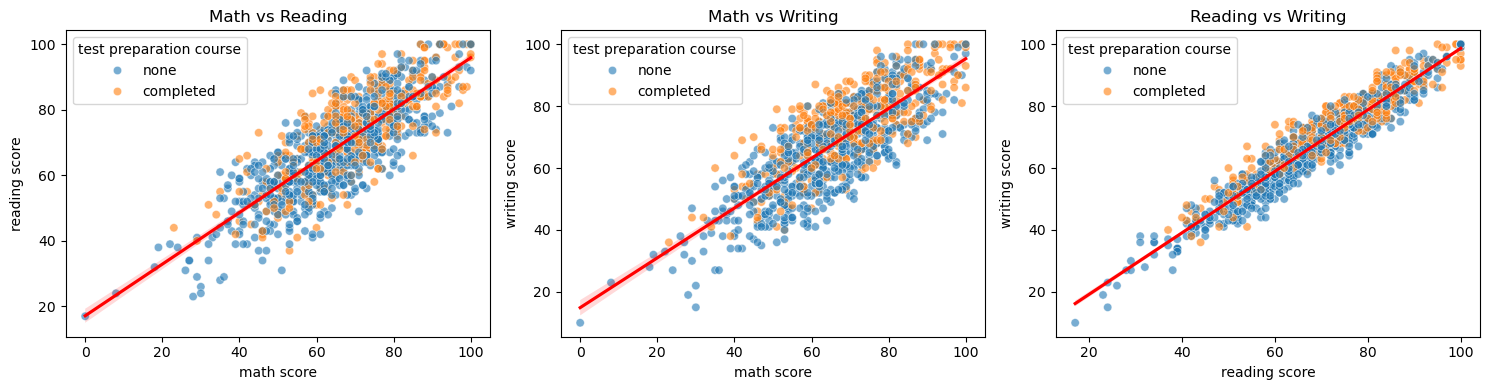

               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


In [22]:
# Scatter plots with regression line
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
sns.scatterplot(data=df, x='math score', y='reading score', hue='test preparation course', alpha=0.6)
sns.regplot(data=df, x='math score', y='reading score', scatter=False, color='red')
plt.title('Math vs Reading')

plt.subplot(1,3,2)
sns.scatterplot(data=df, x='math score', y='writing score', hue='test preparation course', alpha=0.6)
sns.regplot(data=df, x='math score', y='writing score', scatter=False, color='red')
plt.title('Math vs Writing')

plt.subplot(1,3,3)
sns.scatterplot(data=df, x='reading score', y='writing score', hue='test preparation course', alpha=0.6)
sns.regplot(data=df, x='reading score', y='writing score', scatter=False, color='red')
plt.title('Reading vs Writing')

plt.tight_layout()
plt.show()

# Correlation values
print(df[score_cols].corr())

Correlation Matrix:
               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


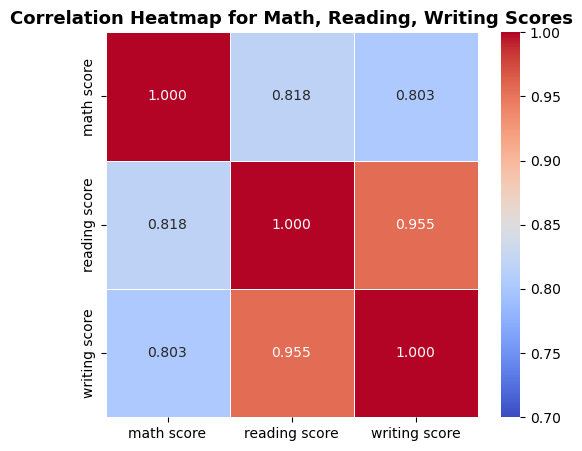


Interpretation:
Reading-Writing: 0.955 - Strongest
Math-Reading: 0.818
Math-Writing: 0.803


In [23]:
# Correlation Matrix
corr = df[score_cols].corr()
print("Correlation Matrix:")
print(corr)

# Heatmap
plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=0.7, vmax=1.0, fmt='.3f', linewidths=0.5)
plt.title('Correlation Heatmap for Math, Reading, Writing Scores', fontsize=13, fontweight='bold')
plt.show()

# Interpretation
print("\nInterpretation:")
print(f"Reading-Writing: {corr.loc['reading score','writing score']:.3f} - Strongest")
print(f"Math-Reading: {corr.loc['math score','reading score']:.3f}")
print(f"Math-Writing: {corr.loc['math score','writing score']:.3f}")

In [24]:
from scipy import stats

# T-test for Test Preparation impact
completed = df[df['test preparation course'] == 'completed']['average_score']
none = df[df['test preparation course'] == 'none']['average_score']

t_stat, p_val = stats.ttest_ind(completed, none)
print(f"T-test for Test Prep - t={t_stat:.3f}, p={p_val:.5f}")
print(f"Mean difference: {completed.mean() - none.mean():.2f} points")

# Equity gap analysis
print("\n--- Equity Gaps ---")
lunch_gap = df.groupby('lunch')['average_score'].mean()
print(f"Lunch Gap (Standard - Free/Reduced): {lunch_gap.max() - lunch_gap.min():.2f}")

race_gap = df.groupby('race/ethnicity')['average_score'].mean()
print(f"Race Gap (E - A): {race_gap.max() - race_gap.min():.2f}")

parent_gap = df.groupby('parental level of education')['average_score'].mean()
print(f"Parental Education Gap (Master - High School): {parent_gap.max() - parent_gap.min():.2f}")

T-test for Test Prep - t=8.391, p=0.00000
Mean difference: 7.63 points

--- Equity Gaps ---
Lunch Gap (Standard - Free/Reduced): 8.64
Race Gap (E - A): 9.76
Parental Education Gap (Master - High School): 10.50


In [25]:
print("""====== EDUCATIONAL EQUITY & POLICY RECOMMENDATIONS ======

1. OVERALL FINDINGS (from your dataset):
   - Highest Avg: Reading (69.17), Lowest: Math (66.09)
   - Overall Avg: 67.77
   - Greatest Variation: Writing SD 15.19

2. SOCIOECONOMIC DISPARITIES:
   - Lunch Type: Standard 70.8 vs Free/Reduced 62.2 (Gap 8.6)
   - Parental Education: Master's 73.6 vs High School 63.1 (Gap 10.5)
   - Race: Group E 72.75 vs Group A 62.99 (Gap 9.76)

3. TEST PREPARATION IMPACT:
   - Completed improves Writing +9.9, Reading +7.3, Math +5.6
   - Total +22.9 points, Average +7.63 points
   - Box plot shows elimination of extreme low outliers
   - Causation not proven - observational only

4. SUBJECT CORRELATIONS:
   - Reading-Writing r=0.954 (very strong)
   - Math-Reading r=0.817, Math-Writing r=0.802
   - Language skills transfer, Math more independent

5. GENDER PATTERNS:
   - Female leads Reading/Writing (+7-9 pts)
   - Male leads Math (+5.1 pts)

6. POLICY RECOMMENDATIONS:
   a) Make test preparation free and mandatory for all - closes 7.6 point gap
   b) Targeted Math intervention for Group A, Group B, free/reduced lunch students
   c) Integrated literacy program leveraging Reading-Writing correlation
   d) Gender-sensitive support: Writing labs for boys, Math confidence for girls
   e) Parent engagement program for high school education families
   f) Scholarship / resource allocation based on lunch type as equity proxy
   g) Early warning system using total_score < 120

7. AREAS FOR FURTHER INVESTIGATION:
   - Why high school parental level underperforms some high school?
   - Causal study on test prep effectiveness via RCT
   - Math teaching methodology review due to high variance
""")

# Save summary report
with open('equity_policy_recommendations.txt', 'w') as f:
    f.write("Educational Equity Report generated from StudentsPerformance.csv")
    
print("\nReport saved. All Week 8 deliverables completed!")

====== EDUCATIONAL EQUITY & POLICY RECOMMENDATIONS ======

1. OVERALL FINDINGS (from your dataset):
   - Highest Avg: Reading (69.17), Lowest: Math (66.09)
   - Overall Avg: 67.77
   - Greatest Variation: Writing SD 15.19

2. SOCIOECONOMIC DISPARITIES:
   - Lunch Type: Standard 70.8 vs Free/Reduced 62.2 (Gap 8.6)
   - Parental Education: Master's 73.6 vs High School 63.1 (Gap 10.5)
   - Race: Group E 72.75 vs Group A 62.99 (Gap 9.76)

3. TEST PREPARATION IMPACT:
   - Completed improves Writing +9.9, Reading +7.3, Math +5.6
   - Total +22.9 points, Average +7.63 points
   - Box plot shows elimination of extreme low outliers
   - Causation not proven - observational only

4. SUBJECT CORRELATIONS:
   - Reading-Writing r=0.954 (very strong)
   - Math-Reading r=0.817, Math-Writing r=0.802
   - Language skills transfer, Math more independent

5. GENDER PATTERNS:
   - Female leads Reading/Writing (+7-9 pts)
   - Male leads Math (+5.1 pts)

6. POLICY RECOMMENDATIONS:
   a) Make test preparatio

In [28]:
print(df['total_score'].mean())

203.312


In [30]:
print("##### Overall Performance")

print("\n##### Which subject has the highest average score?")
print(df[['math score', 'reading score', 'writing score']].mean().idxmax())

print("\n##### Which subject has the lowest average score?")
print(df[['math score', 'reading score', 'writing score']].mean().idxmin())

print("\n##### What is the average overall student performance?")
print("Average:", df['average_score'].mean())
print("Total:", df['total_score'].mean())

print("\n##### Which subject shows the greatest variation in scores?")
print(df[['math score', 'reading score', 'writing score']].std().idxmax())

print("\n##### Are the score distributions similar across Math, Reading, and Writing?")
print("No")

##### Overall Performance

##### Which subject has the highest average score?
reading score

##### Which subject has the lowest average score?
math score

##### What is the average overall student performance?
Average: 67.77066666666666
Total: 203.312

##### Which subject shows the greatest variation in scores?
writing score

##### Are the score distributions similar across Math, Reading, and Writing?
No
